# Lane C(C1·C2) 답변 생성 개선 — 적용 전후 비교 (체크포인트 8문항)

- 비교 대상: C1(답변 길이 통제) 완료 기준 Q11·Q13·Q17·Q18과 C2(요청 항목별 산출 상태) 완료 기준 Q22·Q24·Q25·Q27.
- **적용 전(9-03)**: `latency/traces_full.jsonl` warm 2~4회차 중앙값(Lane A·B 이전). **적용 전(9-05)**: Lane B `traces_rdb_check2_0905.jsonl`·Lane A `traces_graph_check_0905.jsonl` 1회(cold) — SQL은 맞는 행을 냈지만 답변이 버린 상태. **적용 후**: `traces_laneC_c12b_0905.jsonl` 1회(cold). 1차 실행 `traces_laneC_c12_0905.jsonl`(footer 미그룹·상품명 보강 전)은 3절 표에 참고로 남긴다.
- 바뀐 것: `generate_answer_node`가 행 예산을 `sort.limit`(최대 20)·기본 10으로 줄이고, 빈 answer(`[]`·30자 미만)나 길이 초과면 예산 절반으로 1회 재시도, 그래도 없으면 행을 결정론으로 나열한다. 요청 항목마다 산출/미산출과 사유(RDB 컬럼 없음·문서 섹션 없음·편입내역/자회사 데이터 부재)를 LLM 입력에 넣고, 미산출 항목은 답변 끝에 결정론 footer로도 붙인다. `ANSWER_SYSTEM_PROMPT`에 answer 형식(자연어·목록·JSON 금지·"전체 M건 중 N건") 규칙을 추가했다.
- 바뀌지 않은 것: intent·RDB SQL·Graph 로직(C3·C4는 다음 단계). 채점은 `latency/analyze.py`의 루브릭 Claim 채점기를 그대로 부른다.
- 실행: `test/pipline-test/`에서 열면 `latency/`를 자동으로 찾는다. pandas·matplotlib 필요.


In [1]:
import json, csv, math, sys, re, statistics as st
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)

_cands = [Path.cwd() / "latency", Path.cwd() / "test/pipline-test/latency", Path.cwd().parent / "latency"]
LAT = next((p for p in _cands if (p / "traces_full.jsonl").exists()), None)
assert LAT is not None, "latency/ 디렉터리를 찾지 못했습니다"
GOLD = next((p for p in [LAT.parents[1] / "goldset/golden_answers_20260824.csv", LAT.parents[2] / "goldset/golden_answers_20260824.csv"] if p.exists()), None)
sys.path.insert(0, str(LAT)); import analyze  # 루브릭 채점기 재사용

def _font():
    inst = {f.name for f in fm.fontManager.ttflist}
    for n in ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "AppleGothic"]:
        if n in inst: matplotlib.rcParams["font.family"] = n; return n
    for fp in ["C:/Windows/Fonts/malgun.ttf", "/mnt/c/Windows/Fonts/malgun.ttf"]:
        if Path(fp).exists():
            fm.fontManager.addfont(fp); n = fm.FontProperties(fname=fp).get_name(); matplotlib.rcParams["font.family"] = n; return n
    return "(없음)"
FONT = _font(); matplotlib.rcParams["axes.unicode_minus"] = False; matplotlib.rcParams["figure.dpi"] = 110

C1_Q = ["Q11", "Q13", "Q17", "Q18"]; C2_Q = ["Q22", "Q24", "Q25", "Q27"]; QS = C1_Q + C2_Q
TARGET = 15.0

def load(path):
    return [t for t in (json.loads(l) for l in open(path, encoding="utf-8")) if not t.get("superseded")]
def node(t, n): return sum(x["ms"] for x in t["timing"]["nodes"] if x["name"] == n) / 1000
def med(xs): return st.median(xs) if xs else 0.0
def ans_of(t):
    a = t.get("answer") or {}; return str((a.get("answer") if isinstance(a, dict) else a) or "")
def stage_vals(t):
    return {"frame": node(t, "analyze_intent_node") + node(t, "verify_intent_node"), "rdb": node(t, "rdb_search_node"),
            "graph": node(t, "graph_search_node"), "vector": node(t, "vector_search_node"), "generate": node(t, "generate_answer_node")}

before_all = [t for t in load(LAT / "traces_full.jsonl") if t["round"] >= 2 and t["question_id"] in QS]
mid = {}
for f in ("traces_rdb_check2_0905.jsonl", "traces_graph_check_0905.jsonl"):
    for t in load(LAT / f):
        if t["question_id"] in QS and (t["question_id"] not in mid or t["status"] == "ok"): mid[t["question_id"]] = t
after = {}
for t in load(LAT / "traces_laneC_c12b_0905.jsonl"):
    if t["question_id"] not in after or t["status"] == "ok": after[t["question_id"]] = t
first = {}
for t in load(LAT / "traces_laneC_c12_0905.jsonl"):
    if t["question_id"] not in first or t["status"] == "ok": first[t["question_id"]] = t

before = {}
for q in QS:
    runs = [t for t in before_all if t["question_id"] == q and t["status"] == "ok"]
    sv = [stage_vals(t) for t in runs]
    before[q] = {"e2e": med([t["e2e_ms"] / 1000 for t in runs]), "n": len(runs), "ans_len": med([len(ans_of(t)) for t in runs]),
                 **{k: med([s[k] for s in sv]) for k in ("frame", "rdb", "graph", "vector", "generate")}}

golden = {}
if GOLD:
    for r in csv.DictReader(open(GOLD, encoding="utf-8-sig")):
        golden["Q" + r["id"].strip()] = r
cases = {}
for line in open(LAT / "golden_eval.jsonl", encoding="utf-8"):
    c = json.loads(line); cases[c["question_id"]] = c
for q, c in cases.items():
    if q in golden:
        c["question"] = golden[q]["question"]; c["expected_domains"] = analyze.expected_domains(golden[q]["product_category"])
print(f"데이터: {LAT}  · 폰트 {FONT}  · 기준선 warm 회차 {sum(b['n'] for b in before.values())}  · 9-05 Lane A/B {len(mid)}문항  · Lane C 1차 {len(first)}문항 · Lane C 최종 {len(after)}문항")


C:\Users\rladl\anaconda3.5.2.0\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


데이터: C:\Users\rladl\Desktop\2026_MIRAE_ASSET_AI-Festival\2026_10th_MIRAE-ASSET_AI-Festival\test\pipline-test\latency  · 폰트 Malgun Gothic  · 기준선 warm 회차 22  · 9-05 Lane A/B 8문항  · Lane C 1차 8문항 · Lane C 최종 8문항


## 1. E2E 속도 — 9-03 warm p50 · 9-05 Lane A/B · Lane C 적용 후

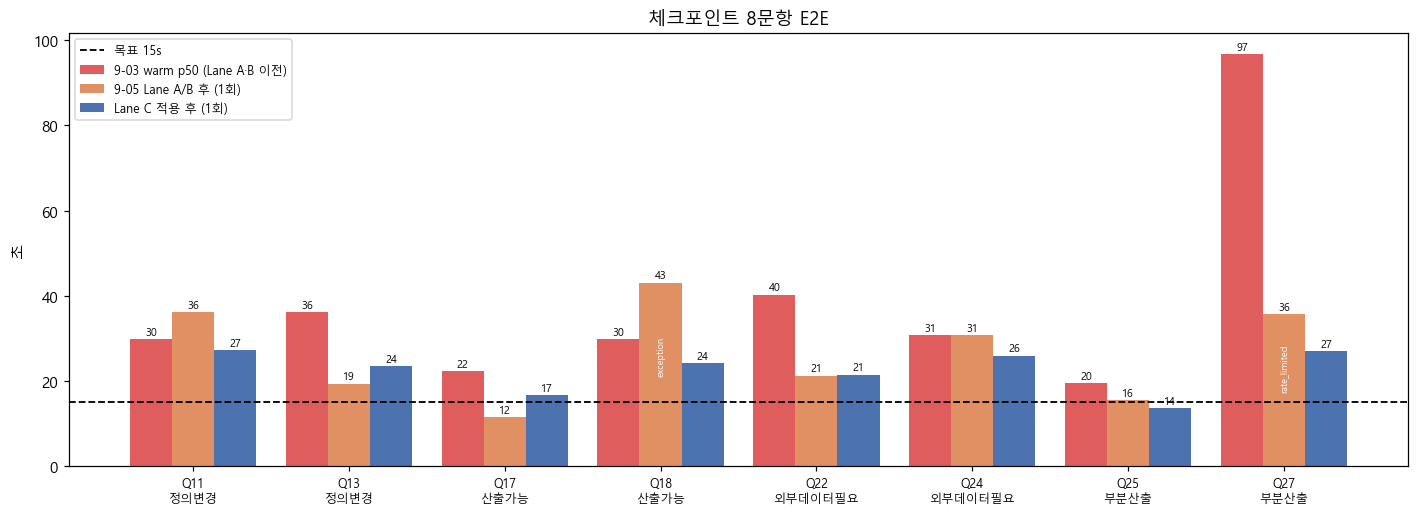

15s 이내: 9-03 0/8 → Lane A/B 1/8 → Lane C 1/8


In [2]:
x = np.arange(len(QS)); w = 0.27
b = [before[q]["e2e"] for q in QS]; m = [mid[q]["e2e_ms"] / 1000 if q in mid else 0 for q in QS]; a = [after[q]["e2e_ms"] / 1000 if q in after else 0 for q in QS]
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(x - w, b, w, color="#d62728", alpha=0.75, label="9-03 warm p50 (Lane A·B 이전)")
ax.bar(x, m, w, color="#dd8452", alpha=0.9, label="9-05 Lane A/B 후 (1회)")
ax.bar(x + w, a, w, color="#4c72b0", label="Lane C 적용 후 (1회)")
ax.axhline(TARGET, color="black", ls="--", lw=1.2, label="목표 15s")
for i, q in enumerate(QS):
    for off, v, src in ((-w, b[i], None), (0, m[i], mid.get(q)), (w, a[i], after.get(q))):
        ax.text(i + off, v + 1, f"{v:.0f}", ha="center", fontsize=7)
        if src is not None and src["status"] != "ok": ax.text(i + off, v / 2, src["status"], ha="center", fontsize=6, color="white", rotation=90)
ax.set_xticks(x); ax.set_xticklabels([f"{q}\n{golden.get(q, {}).get('data_status', '')}" for q in QS], fontsize=8)
ax.set_ylabel("초"); ax.set_title("체크포인트 8문항 E2E"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"15s 이내: 9-03 {sum(1 for v in b if v <= TARGET)}/8 → Lane A/B {sum(1 for v in m if 0 < v <= TARGET)}/8 → Lane C {sum(1 for v in a if 0 < v <= TARGET)}/8")


## 2. 답변 생성 단계 — generate 시간과 answer 길이

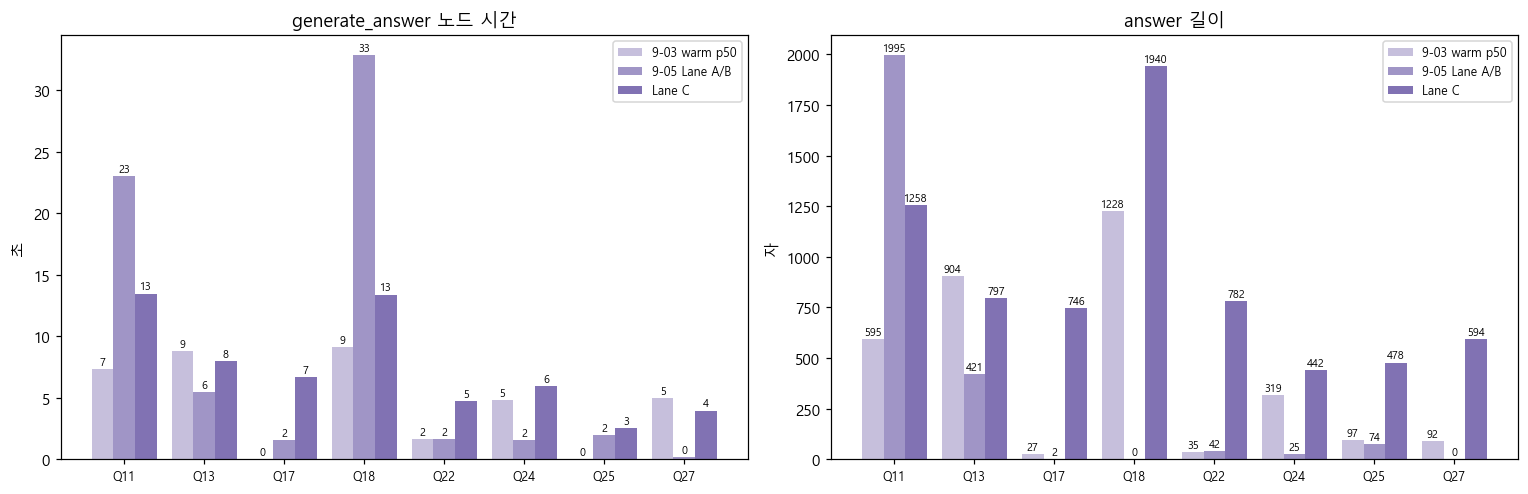

Lane A/B 시점: Q17 answer '[]'(2자), Q18 예외(0자), Q24 '답변을 제공할 수 없습니다'(21자). Lane C 시점의 길이는 상품명·항목·미산출 footer를 포함한 값이다.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
gb = [before[q]["generate"] for q in QS]; gm = [node(mid[q], "generate_answer_node") if q in mid else 0 for q in QS]; ga = [node(after[q], "generate_answer_node") if q in after else 0 for q in QS]
lb = [before[q]["ans_len"] for q in QS]; lm = [len(ans_of(mid[q])) if q in mid else 0 for q in QS]; la = [len(ans_of(after[q])) if q in after else 0 for q in QS]
for ax, (vb, vm, va), title, unit in [(axes[0], (gb, gm, ga), "generate_answer 노드 시간", "초"), (axes[1], (lb, lm, la), "answer 길이", "자")]:
    ax.bar(x - w, vb, w, color="#8172b3", alpha=0.45, label="9-03 warm p50"); ax.bar(x, vm, w, color="#8172b3", alpha=0.75, label="9-05 Lane A/B"); ax.bar(x + w, va, w, color="#8172b3", label="Lane C")
    for i in range(len(QS)):
        for off, v in ((-w, vb[i]), (0, vm[i]), (w, va[i])): ax.text(i + off, v + max(va + vb + vm) * 0.01, f"{v:.0f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(QS, fontsize=8); ax.set_ylabel(unit); ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Lane A/B 시점: Q17 answer '[]'(2자), Q18 예외(0자), Q24 '답변을 제공할 수 없습니다'(21자). Lane C 시점의 길이는 상품명·항목·미산출 footer를 포함한 값이다.")


## 3. 답변 상태 — 빈 답변·예외·재시도·형식

In [4]:
def gen_err(t): return "; ".join(str(x.get("error"))[:80] for x in t["timing"]["nodes"] if x["name"] == "generate_answer_node" and x.get("error"))
def shape(t):
    s = ans_of(t).strip()
    if t["status"] != "ok" and not s: return f"예외({t['status']})"
    if not s or s in ("[]", "[", "{}"): return "빈 답변"
    if s.startswith("[") or s.startswith("{"): return "JSON 문자열"
    if len(s) < 30: return "머리말만"
    return "자연어"
def retry_msgs(t): return [m for m in t.get("trace_messages") or [] if m.startswith("답변 생성")]
rows = []
for q in QS:
    t = after.get(q); mt = mid.get(q)
    ft = first.get(q)
    rows.append({"ID": q, "9-05 Lane A/B 답변 상태": shape(mt) + (f" ({gen_err(mt)})" if gen_err(mt) else "") if mt else "-",
                 "Lane C 1차": shape(ft) if ft else "-", "Lane C 답변 상태": shape(t) if t else "-", "Lane C 재시도·폴백 기록": " / ".join(retry_msgs(t)) if t else "-",
                 "행 수(merged)": t.get("merged_rows_total") if t else "-",
                 "'전체 M건 중 N건' 표기": ("O" if re.search(r"전체\s*\d+건\s*중", ans_of(t)) else "X") if t else "-",
                 "미산출 footer": ("O" if "확인할 수 없는 항목" in ans_of(t) else "-") if t else "-"})
display(pd.DataFrame(rows).set_index("ID"))


,9-05 Lane A/B 답변 상태,Lane C 1차,Lane C 답변 상태,Lane C 재시도·폴백 기록,행 수(merged),'전체 M건 중 N건' 표기,미산출 footer
ID,,,,,,,
Q11,자연어,자연어,자연어,"답변 생성 완료 (100건 기반, 10건 표시)",100,X,O
Q13,JSON 문자열,자연어,자연어,"답변 생성 완료 (10건 기반, 10건 표시)",10,X,O
Q17,빈 답변,자연어,자연어,"답변 생성 완료 (14건 기반, 10건 표시)",14,X,-
Q18,예외(exception) (LengthFinishReasonError: Could not parse response content as the length limit wa),자연어,자연어,"답변 생성 완료 (10건 기반, 10건 표시)",10,X,-
Q22,자연어,자연어,자연어,"답변 생성 완료 (100건 기반, 10건 표시)",100,X,O
Q24,머리말만,자연어,자연어,"답변 생성 1회차: answer가 비어 있음 / 답변 생성 완료 (1건 기반, 1건 표시) / 답변 생성 완료 (1건 기반, 1건 표시)",1,X,O
Q25,자연어,자연어,자연어,"답변 생성 완료 (4건 기반, 4건 표시)",4,X,O
Q27,예외(rate_limited) (RateLimitError: Error code: 429 - {'error': {'message': 'Too many requests: rate),자연어,자연어,"답변 생성 완료 (200건 기반, 10건 표시)",200,X,O


## 4. 루브릭 Claim 채점 — 골든 대조 (analyze.py 채점기)

,유형,9-03 정답(warm),9-05 Lane A/B,Lane A/B 실패 Claim,Lane C,Lane C 실패 Claim,Lane C 원인
ID,,,,,,,
Q11,정의변경,0/2,O,-,O,-,
Q13,정의변경,0/2,X,"C1:MISSING_DEFINITION_EXPLANATION, C5:GENERATION_OMISSION",X,C5:GENERATION_OMISSION,E
Q17,산출가능,0/3,X,"C2:GENERATION_OMISSION, C3:GENERATION_OMISSION, C4:GENERATION_OMISSION, C5:GENERATION_OMISSION, C6:GENERATION_OMISSION, M0:GENERATION_OMISSION",O,-,
Q18,산출가능,0/3,X,"C2:GENERATION_OMISSION, C6:GENERATION_OMISSION",O,-,
Q22,외부데이터필요,1/3,O,-,O,-,
Q24,외부데이터필요,2/3,X,"C1:GENERATION_OMISSION, C2:GENERATION_OMISSION, C3:GENERATION_OMISSION, C5:GENERATION_OMISSION, M0:GENERATION_OMISSION",O,-,
Q25,부분산출,0/3,X,"C2:RETRIEVAL_MISS, C3:RETRIEVAL_MISS, C4:RETRIEVAL_MISS",X,"C2:RETRIEVAL_MISS, C3:RETRIEVAL_MISS, C4:RETRIEVAL_MISS",C
Q27,부분산출,0/3,X,-,X,"C1:RETRIEVAL_MISS, C2:GENERATION_OMISSION, C3:RETRIEVAL_MISS",C


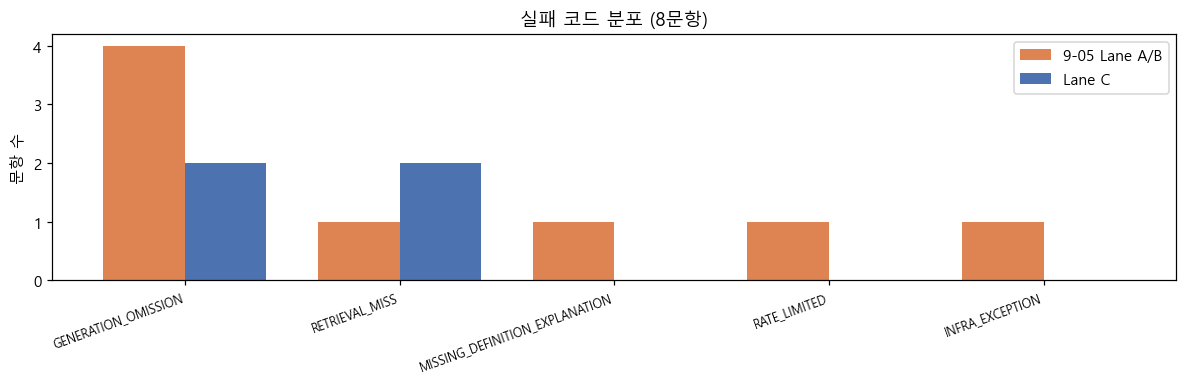

In [5]:
def ev(q, t):
    e = analyze.evaluate(cases[q], t); crs = e["claim_results"]
    return e, ", ".join(f"{c['claim_id']}:{c['diagnosis']}" for c in crs if c["severity"] in ("ERROR", "CRITICAL")) or "-"
rows = []
for q in QS:
    bruns = [t for t in before_all if t["question_id"] == q and t["status"] == "ok"]
    bpass = [analyze.evaluate(cases[q], t)["overall_pass"] for t in bruns]
    em, fm_ = ev(q, mid[q]) if q in mid else (None, "-"); ea, fa = ev(q, after[q]) if q in after else (None, "-")
    rows.append({"ID": q, "유형": golden.get(q, {}).get("data_status", ""), "9-03 정답(warm)": f"{sum(bpass)}/{len(bpass)}",
                 "9-05 Lane A/B": ("O" if em["overall_pass"] else "X") if em else "-", "Lane A/B 실패 Claim": fm_,
                 "Lane C": ("O" if ea["overall_pass"] else "X") if ea else "-", "Lane C 실패 Claim": fa, "Lane C 원인": ea["cause"] if ea else "-"})
score = pd.DataFrame(rows).set_index("ID"); display(score)
fig, ax = plt.subplots(figsize=(11, 3.6))
codes_m = Counter(c for q in QS if q in mid for c in analyze.evaluate(cases[q], mid[q])["failure_codes"])
codes_a = Counter(c for q in QS if q in after for c in analyze.evaluate(cases[q], after[q])["failure_codes"])
keys = sorted(set(codes_m) | set(codes_a), key=lambda k: -(codes_m[k] + codes_a[k])); xx = np.arange(len(keys))
ax.bar(xx - 0.19, [codes_m[k] for k in keys], 0.38, color="#dd8452", label="9-05 Lane A/B"); ax.bar(xx + 0.19, [codes_a[k] for k in keys], 0.38, color="#4c72b0", label="Lane C")
ax.set_xticks(xx); ax.set_xticklabels(keys, rotation=20, ha="right", fontsize=8); ax.set_ylabel("문항 수"); ax.set_title("실패 코드 분포 (8문항)"); ax.legend(); plt.tight_layout(); plt.show()


## 5. 요청 항목별 산출 상태 — 답변이 미산출 사유를 말하는가

In [6]:
rows = []
for q in C2_Q:
    if q not in after: continue
    t = after[q]; ans = ans_of(t); c = cases[q]
    gaps = [cl for cl in c["claims"] if cl["availability"] in ("external_required", "partial")]
    for cl in gaps:
        toks = cl.get("gap_tokens") or []
        hit = [tk for tk in toks if tk.lower() in ans.lower()]
        rows.append({"ID": q, "Claim": f"{cl['claim_id']} {cl['label']}", "availability": cl["availability"], "부재 고지 토큰 일치": ", ".join(hit[:4]) or "없음", "판정": "O" if hit else "X"})
display(pd.DataFrame(rows).set_index(["ID", "Claim"]))
for q in C2_Q:
    if q in after:
        foot = ans_of(after[q]).split("제공된 데이터로 확인할 수 없는 항목:")
        print(f"[{q}] footer: {foot[1].strip()[:400] if len(foot) > 1 else '(없음)'}")


availability           부재 고지 토큰 일치 판정
ID  Claim                                                                  
Q22 C1 캠브리콘 편입 관계(ETF→편입증권→기업)   external_required  편입내역, 보유종목, 캠브리콘, 외부  O
    C2 편입비중·편입기준일                external_required   편입내역, 보유종목, 비중, 기준일  O
    C3 편입내역 문서명·근거 문장            external_required     문서, 근거 문장, 외부, 필요  O
Q24 C1 에코프로 자회사 관계               external_required           외부, 필요, 미확보  O
    C2 자회사 ETF 편입 관계             external_required    편입내역, 보유종목, 외부, 필요  O
    C3 편입비중·기준일                  external_required   편입내역, 보유종목, 비중, 기준일  O
    C4 ETF AUM·기준일(대상 ETF 특정 시)            partial        기준일, 없, 외부, 필요  O
    C5 위험요인 문서 인용                external_required        위험, 문서, 인용, 외부  O
Q25 C5 운용주체·자금조달·투자전략 동향(공식 문서)  external_required  문서, 정책자료, 운용자료, 발표기관  O
Q27 C4 모자회사 관계 공식 근거             external_required     자회사, 모자회사, 외부, 필요  O
    C5 ETF 편입비중                  external_required    편입내역, 보유종목, 비중, 외부  O
    C6 배터리산업 위험요인 문서             external_required        위험, 문서, 외부, 필요  O

[Q22] footer: 편입비중, 편입기준일, 편입내역 문서명 — 편입내역(보유종목·편입비중·편입기준일) 데이터가 주최측 원천에 없어 외부 데이터가 필요함; 근거 문장 — 해외ETF 데이터에 대응 컬럼이 없음; 캠브리콘 holds 관계 — 편입내역(보유종목·편입비중·편입기준일) 데이터가 주최측 원천에 없어 외부 데이터가 필요함 (그래프에서 해당 엔티티를 찾지 못함)
수치 기준일: 해외ETF 2026-08-22 (주최측 배포 2026-08-24)
[Q24] footer: 편입비중 — 편입내역(보유종목·편입비중·편입기준일) 데이터가 주최측 원천에 없어 외부 데이터가 필요함; 위험요인 문서 인용문 — 문서에 투자위험 섹션이 없어 근거 문서 미확보; R2 holds 관계 — 편입내역(보유종목·편입비중·편입기준일) 데이터가 주최측 원천에 없어 외부 데이터가 필요함 (그래프에서 해당 엔티티를 찾지 못함)
수치 기준일: 국내ETF 2026-08-22 (주최측 배포 2026-08-24)
[Q25] footer: 구조, 운용주체, 자금조달 방식, 최근 투자전략 동향 — 펀드 데이터에 대응 컬럼이 없음; 공식 정책자료, 운용자료, 발표기관, 발행일, 근거 문장 — 근거 문서 미확보(문서 검색 no_document)
수치 기준일: 펀드 2026-08-21 (주최측 배포 2026-08-24)
[Q27] footer: 모자회사 관계의 공식 근거 — 채권 데이터에 대응 컬럼이 없음; 채권 신용등급·만기 — 국내ETF 데이터에 대응 컬럼이 없음; ETF 편입비중 — 편입내역(보유종목·편입비중·편입기준일) 데이터가 주최측 원천에 없어 외부 데이터가 필요함; 배터리산업 위험요인 — 문서에 투자위험 섹션이 없어 근거 문서 미확보; 근거 문서별 구분 — 근거 문서 미확보(문서 검색 topic_not_covered); LG에너지솔루션 holds 관계 — 편입내역(보유종목·편입비중·편입기준일) 데이터가 주최측 원천에 없어 외부 데이터가 필요함 (그래프에서 해당 엔티티를 찾지 못함)
수치 기준일:

## 6. 답변 전문 vs 골든 정답

In [7]:
rows = []
for q in QS:
    g = golden.get(q, {}); mt = mid.get(q); t = after.get(q)
    def cell(tr):
        if not tr: return "(미측정)"
        err = "; ".join(str(e.get("error", ""))[:120] for e in (tr.get("errors") or []) if isinstance(e, dict))
        return (ans_of(tr).strip() or "(답변 없음)") + (f"\n⚠ {err}" if err else "")
    rows.append({"ID": q, "유형": f"{g.get('type','')}\n[{g.get('data_status','')}]", "상태 / E2E (Lane C)": f"{t['status']} / {t['e2e_ms']/1000:.1f}s" if t else "-",
                 "질문": g.get("question", ""), "9-05 Lane A/B 답변": cell(mt), "Lane C 답변": cell(t), "골든 정답": g.get("golden_answer", "")})
ans_df = pd.DataFrame(rows).set_index("ID")
display(ans_df.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left", "vertical-align": "top", "font-size": "11px"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("font-size", "11px")]}]))


,유형,상태 / E2E (Lane C),질문,9-05 Lane A/B 답변,Lane C 답변,골든 정답
ID,,,,,,
Q11,조건검색_채권신용등급 [정의변경],ok / 27.3s,"최신 갱신일 기준 매수가능수량이 0보다 큰 원화채권 중 신용등급이 AA- 이상인 종목을 알려줘. 상품명, 발행사, 원등급, 만기일, 매수수익률, 매수가능수량과 기준일을 제시해줘.","조건에 맞는 원화채권 목록은 다음과 같습니다: 1. 상품명: 퍼스트파이브지제팔십사차유동화전문1-14, 발행사: 퍼스트파이브지제팔십사차유동화전문, 원등급: AAA, 만기일: 2027-02-23, 매수수익률: -, 매수가능수량: "", 기준일: "". 2. 상품명: 경기주택도시공사24-10-83(지), 발행사: 경기주택도시공사, 원등급: AAA, 만기일: 2027-10-25, 매수수익률: -, 매수가능수량: "", 기준일: "". 3. 상품명: 한국주택금융공사 MBS2015-11(1-8)(콜), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2035-06-02, 매수수익률: -, 매수가능수량: "", 기준일: "". 4. 상품명: POSCO314-1, 발행사: (주)포스코, 원등급: AA+, 만기일: 2027-01-14, 매수수익률: -, 매수가능수량: "", 기준일: "". 5. 상품명: 한국주택금융공사 MBS2016-8(1-7)(콜), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2031-04-08, 매수수익률: -, 매수가능수량: "", 기준일: "". 6. 상품명: 한국주택금융공사 214(사), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2029-04-28, 매수수익률: -, 매수가능수량: "", 기준일: "". 7. 상품명: 수산금융채권(일반) 03-11이표120-07호, 발행사: 수산업협동조합중앙회, 원등급: AAA, 만기일: 2026-11-07, 매수수익률: -, 매수가능수량: "", 기준일: "". 8. 상품명: 한국철도공사276, 발행사: 한국철도공사, 원등급: AAA, 만기일: 2055-11-06, 매수수익률: -, 매수가능수량: "", 기준일: "". 9. 상품명: 한국도로공사468, 발행사: 한국도로공사, 원등급: AAA, 만기일: 2039-04-21, 매수수익률: -, 매수가능수량: "", 기준일: "". 10. 상품명: 한국도로공사고속도로건설채권 783, 발행사: 한국도로공사, 원등급: AAA, 만기일: 2041-11-11, 매수수익률: -, 매수가능수량: "", 기준일: "". 11. 상품명: 한국주택금융공사 MBS2019-5(1-7)(콜), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2034-02-22, 매수수익률: -, 매수가능수량: "", 기준일: "". 12. 상품명: 한국수자원공사289, 발행사: 한국수자원공사, 원등급: AAA, 만기일: 2030-08-22, 매수수익률: -, 매수가능수량: "", 기준일: "". 13. 상품명: SK이노베이션11-2, 발행사: SK이노베이션(주), 원등급: AA0, 만기일: 2027-07-27, 매수수익률: -, 매수가능수량: "", 기준일: "". 14. 상품명: LG전자95-1, 발행사: LG전자(주), 원등급: AA0, 만기일: 2027-02-25, 매수수익률: -, 매수가능수량: "", 기준일: "". 15. 상품명: 한국주택금융공사 288(사), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2028-12-26, 매수수익률: -, 매수가능수량: "", 기준일: "". 16. 상품명: 대구교통공사57, 발행사: 대구교통공사, 원등급: AA+, 만기일: 2028-11-10, 매수수익률: -, 매수가능수량: "", 기준일: "". 17. 상품명: 한국주택금융공사 152(사), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2027-05-13, 매수수익률: -, 매수가능수량: "", 기준일: "". 18. 상품명: 국가철도공단채권 190, 발행사: 국가철도공단, 원등급: AAA, 만기일: 2031-09-29, 매수수익률: -, 매수가능수량: "", 기준일: "". 19. 상품명: 한국철도공사210, 발행사: 한국철도공사, 원등급: AAA, 만기일: 2027-03-04, 매수수익률: -, 매수가능수량: "", 기준일: "". 20. 상품명: 한국주택금융공사 MBS2021-6(1-7)(사)(콜), 발행사: 한국주택금융공사, 원등급: AAA, 만기일: 2036-03-26, 매수수익률: -, 매수가능수량: "", 기준일: "".","다음은 해당 조건을 만족하는 채권들입니다: 1. 퍼스트파이브지제팔십사차유동화전문1-14 - 발행사: 퍼스트파이브지제팔십사차유동화전문, 신용등급: AAA, 만기일: 2027년 2월 23일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 2. 경기주택도시공사24-10-83(지) - 발행사: 경기주택도시공사, 신용등급: AAA, 만기일: 2027년 10월 25일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 3. 한국주택금융공사 MBS2015-11(1-8)(콜) - 발행사: 한국주택금융공사, 신용등급: AAA, 만기일: 2035년 6월 2일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 4. POSCO314-1 - 발행사: (주)포스코, 신용등급: AA+, 만기일: 2027년 1월 14일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 5. 한국주택금융공사 MBS2016-8(1-7)(콜) - 발행사: 한국주택금융공사, 신용등급: AAA, 만기일: 2031년 4월 8일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 6. 한국주택금융공사 214(사) - 발행사: 한국주택금융공사, 신용등급: AAA, 만기일: 2029년 4월 28일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 7. 수산금융채권(일반) 03-11이표120-07호 - 발행사: 수산업협동조합중앙회, 신용등급: AAA, 만기일: 2026년 11월 7일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 8. 한국철도공사276 - 발행사: 한국철도공사, 신용등급: AAA, 만기일: 2055년 11월 6일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 9. 한국도로공사468 - 발행사: 한국도로공사, 신용등급: AAA, 만기일: 2039년 4월 21일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 10. 한국도로공사고속도로건설채권 783 - 발행사: 한국도로공사, 신용등급: AAA, 만기일: 2041년 11월 11일, 매수수익률: 값 없음, 매수가능수량: 값 없음, 기준일: 값 없음. 제공된 데이터로 확인할 수 없는 항목: 매수가능수량 — buyable_quantity 컬럼은 주최측이 무효로 공지해 사용하지 않음(구매 가능 여부는 공지대로 상장폐지·리스팅 종료 종목을 제외한 전 종목으로 봄) 수치 기준일: 채권 2026-08-21 (주최측 배포 2026-08-24)","주최측이 buyable_quantity를 무효 처리했으므로 '매수가능수량>0' 조건은 적용하지 않는다. 구매가능(만기 미도래)·원화·AA- 이상 = 15,992행 / 고유 15,806종목. 등급 분포 AAA 8,703, AA- 3,512, AA+ 2,537, AA0 1,240. 예시: 중소벤처기업진흥채권 703(사)(AAA, 만기 20300910, 민평 4.233); 한국도로공사고속도로건설채권 946(AAA, 만기 20350508, 민평 4.494); 한국도로공사고속도로건설채권1001(AAA, 만기 20310415, 민평 4.346); 한국도로공사고속도로건설채권1012(AAA, 만기 20310724, 민평 4.376); 한국전력공사채권1108(AAA, 만기 20311216, 민평 4.476)"
Q13,조건검색_채권복합조건 [정의변경],ok / 23.6s,"매수 가능한 회사채 중 AA- 이상이고 잔존기간이 3년 이하인 종목을 매수수익률 순으로 상위 10개 알려줘. 등급 서열 규칙, 잔존일수, 수익률, 매수가능수량을 함

## 7. 판정

In [8]:
def verdict(q):
    t = after.get(q)
    if not t: return "미측정"
    if t["status"] != "ok": return f"측정 불가({t['status']})"
    ans = ans_of(t); e = analyze.evaluate(cases[q], t)
    if e["overall_pass"]: return "PASS"
    fails = [c for c in e["claim_results"] if c["severity"] in ("ERROR", "CRITICAL")]
    gen = [c for c in fails if c["diagnosis"] == "GENERATION_OMISSION"]; ret = [c for c in fails if c["diagnosis"] in ("RETRIEVAL_MISS", "STALE_DEFINITION", "FILTER_ERROR")]
    parts = []
    if gen: parts.append("생성 누락: " + ", ".join(c["claim"] for c in gen))
    if ret: parts.append("검색 단계(Lane C 범위 밖): " + ", ".join(c["claim"] for c in ret))
    other = [c for c in fails if c not in gen and c not in ret]
    if other: parts.append("기타: " + ", ".join(f"{c['claim']}({c['diagnosis']})" for c in other))
    return " / ".join(parts) or "검토 필요"
vt = pd.DataFrame([{"ID": q, "E2E 9-03→A/B→C": f"{before[q]['e2e']:.0f}s → {mid[q]['e2e_ms']/1000:.0f}s → {after[q]['e2e_ms']/1000:.0f}s" if q in mid and q in after else "-",
                    "generate 전→후": f"{node(mid[q],'generate_answer_node'):.1f}s → {node(after[q],'generate_answer_node'):.1f}s" if q in mid and q in after else "-",
                    "15s 이내": ("O" if after[q]["e2e_ms"] <= 15000 else "X") if q in after else "-", "답변 상태": shape(after[q]) if q in after else "-", "판정": verdict(q)} for q in QS]).set_index("ID")
display(vt)
print("C1 완료 기준: Q11·Q13·Q17·Q18 답변 예외 0, answer 비어 있지 않음, 상품명·요청 필드 포함 — 위 3·4절 표로 확인.")
print("C2 완료 기준: Q22·Q24·Q27이 필요한 데이터 종류를 명시, Q25가 '상품은 존재하나 항목은 데이터에 없음' — 5절 토큰 일치와 6절 전문으로 확인.")


,E2E 9-03→A/B→C,generate 전→후,15s 이내,답변 상태,판정
ID,,,,,
Q11,30s → 36s → 27s,23.0s → 13.5s,X,자연어,PASS
Q13,36s → 19s → 24s,5.5s → 8.0s,X,자연어,생성 누락: 수익률 상위 10
Q17,22s → 12s → 17s,1.6s → 6.7s,X,자연어,PASS
Q18,30s → 43s → 24s,32.8s → 13.4s,X,자연어,PASS
Q22,40s → 21s → 21s,1.7s → 4.7s,X,자연어,PASS
Q24,31s → 31s → 26s,1.6s → 5.9s,X,자연어,PASS
Q25,20s → 16s → 14s,2.0s → 2.6s,O,자연어,"검색 단계(Lane C 범위 밖): 구조/펀드유형, 벤치마크, 순자산"
Q27,97s → 36s → 27s,0.2s → 4.0s,X,자연어,"생성 누락: 채권 신용등급 / 검색 단계(Lane C 범위 밖): (주)엘지에너지솔루션 발행 채권(발행사/상품명 필터), 채권 만기"


C1 완료 기준: Q11·Q13·Q17·Q18 답변 예외 0, answer 비어 있지 않음, 상품명·요청 필드 포함 — 위 3·4절 표로 확인.
C2 완료 기준: Q22·Q24·Q27이 필요한 데이터 종류를 명시, Q25가 '상품은 존재하나 항목은 데이터에 없음' — 5절 토큰 일치와 6절 전문으로 확인.
